<a href="https://colab.research.google.com/github/asama0/ML-proj/blob/main/English_OCR_CRNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# English OCR from scratch — CRNN + CTC (PyTorch)

This notebook trains your **own** OCR model for printed English text lines.

**Pipeline**
1. Generate synthetic text-line images (real English sentences × many fonts × augmentations)
2. Train a **CRNN**: CNN feature extractor → BiLSTM sequence model → per-timestep character probabilities
3. Train with **CTC loss** (no need for character-level alignment)
4. Decode with greedy CTC, measure **CER** (character error rate)
5. Run on your own images (simple line segmentation + recognition)

> Runtime → Change runtime type → **GPU (T4 is fine)** before running.


## 1. Setup

In [1]:
!apt-get -qq install -y fonts-dejavu fonts-liberation fonts-freefont-ttf fonts-noto-core > /dev/null
!pip -q install editdistance

import os, glob, random, string, math, time
import numpy as np
import cv2
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageDraw, ImageFont, ImageFilter
import editdistance
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cuda


## 2. Character set & text corpus
We use real English sentences (Brown corpus) so the model learns natural letter patterns, mixed with some random strings (numbers, codes, punctuation) so it doesn't just memorise words.

In [2]:
CHARSET = string.ascii_letters + string.digits + string.punctuation + ' '
char2idx = {c: i + 1 for i, c in enumerate(CHARSET)}   # 0 is reserved for the CTC blank
idx2char = {i: c for c, i in char2idx.items()}
NUM_CLASSES = len(CHARSET) + 1
MAX_LEN = 32          # max characters per synthetic line

import nltk
nltk.download('brown', quiet=True)
from nltk.corpus import brown
words = [w for w in brown.words() if all(c in char2idx for c in w)]
print(f'{len(words):,} corpus tokens, {NUM_CLASSES} classes')

def detok(tokens):
    s = ' '.join(tokens)
    for p in [' ,', ' .', ' ;', ' :', ' !', ' ?', " '", ' )']:
        s = s.replace(p, p[1:])
    return s.replace('( ', '(')

def random_text():
    r = random.random()
    if r < 0.75:                      # natural English snippet
        start = random.randrange(len(words) - 20)
        s = detok(words[start:start + random.randint(1, 8)])
    elif r < 0.9:                     # numbers / dates / prices / codes
        s = random.choice([
            f'{random.randint(0, 99999)}',
            f'{random.randint(1,28):02d}/{random.randint(1,12):02d}/{random.randint(1950,2030)}',
            f'${random.randint(0,9999)}.{random.randint(0,99):02d}',
            f'{random.randint(0,100)}%',
            ''.join(random.choices(string.ascii_uppercase + string.digits, k=random.randint(4, 10))),
        ])
    else:                             # random characters (forces true per-char reading)
        s = ''.join(random.choices(CHARSET, k=random.randint(3, 20))).strip() or 'a'
    if random.random() < 0.15: s = s.upper()
    if random.random() < 0.10: s = s.lower()
    return s[:MAX_LEN].strip() or 'ok'

for _ in range(8): print(repr(random_text()))

1,161,192 corpus tokens, 96 classes
'the corner, a block from Columbu'
'community, nor does any answer'
'. THEREFORE, N IS INVERSELY PROP'
'countries passing'
'n"?D`HhCcA60DT?{]FzH'
'consequences of this'
'unusually large head. dr. lalaur'
'parts'


## 3. Synthetic image generator

312 fonts


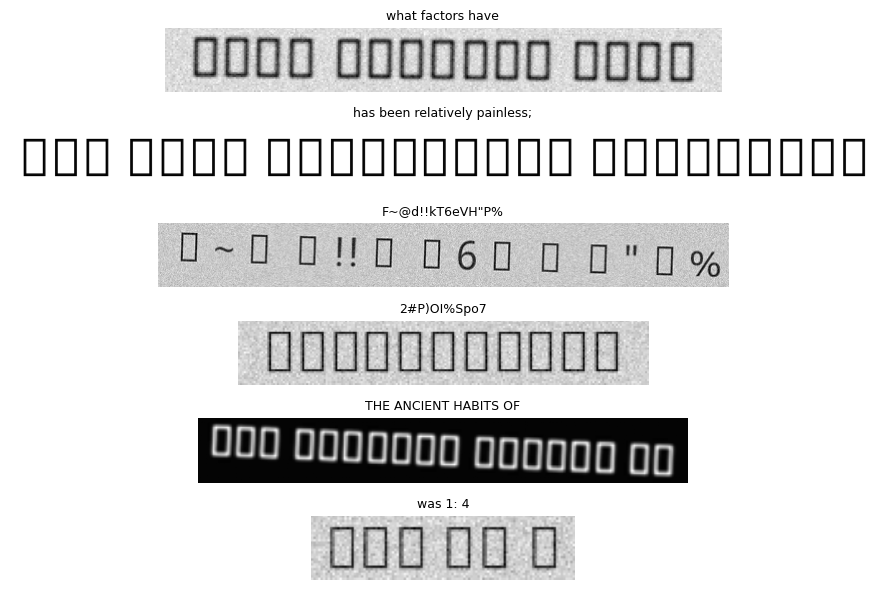

In [3]:
FONTS = [f for f in glob.glob('/usr/share/fonts/truetype/**/*.ttf', recursive=True)
         if not any(b in f.lower() for b in ['symbol', 'emoji', 'math', 'music', 'braille'])]
# keep only fonts that can actually render our charset
def font_ok(path):
    try:
        f = ImageFont.truetype(path, 24)
        return f.getbbox('Ag9$')[2] > 0
    except Exception:
        return False
FONTS = [f for f in FONTS if font_ok(f)]
print(len(FONTS), 'fonts')

IMG_H = 32
MAX_W = 512

def render(text):
    font = ImageFont.truetype(random.choice(FONTS), random.randint(22, 44))
    l, t, r, b = font.getbbox(text)
    pad_x, pad_y = random.randint(2, 16), random.randint(2, 12)
    W, H = (r - l) + 2 * pad_x, (b - t) + 2 * pad_y
    bg = random.randint(170, 255); fg = random.randint(0, max(0, bg - 120))
    img = Image.new('L', (W, H), bg)
    ImageDraw.Draw(img).text((pad_x - l, pad_y - t), text, font=font, fill=fg)

    # augmentations
    if random.random() < 0.4:
        img = img.rotate(random.uniform(-2.5, 2.5), resample=Image.BICUBIC, expand=True, fillcolor=bg)
    if random.random() < 0.3:
        img = img.filter(ImageFilter.GaussianBlur(random.uniform(0.3, 1.2)))
    a = np.array(img).astype(np.float32)
    if random.random() < 0.5:
        a += np.random.normal(0, random.uniform(2, 15), a.shape)
    if random.random() < 0.2:   # simulate scan/low-res
        h, w = a.shape; s = random.uniform(0.4, 0.8)
        a = cv2.resize(cv2.resize(a, (max(1, int(w*s)), max(1, int(h*s)))), (w, h))
    if random.random() < 0.05:  # occasional light-on-dark text
        a = 255 - a
    return np.clip(a, 0, 255).astype(np.uint8)

def preprocess(gray):
    # gray uint8 (H, W) -> float tensor (1, 32, W), text bright on black background
    if gray.mean() < 127:            # make it dark text on light background first
        gray = 255 - gray
    h, w = gray.shape
    new_w = max(8, min(MAX_W, int(round(w * IMG_H / h))))
    g = cv2.resize(gray, (new_w, IMG_H), interpolation=cv2.INTER_AREA)
    x = 1.0 - g.astype(np.float32) / 255.0   # text -> 1, background -> 0 (so zero padding is "blank paper")
    return torch.from_numpy(x).unsqueeze(0)

fig, axs = plt.subplots(6, 1, figsize=(10, 6))
for ax in axs:
    t = random_text(); ax.imshow(render(t), cmap='gray'); ax.set_title(t, fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

## 4. Dataset & batching
Images are generated on the fly, so every epoch sees new samples (infinite data, no overfitting to a fixed set). The validation set is fixed with a seed.

In [4]:
class SynthOCR(Dataset):
    def __init__(self, n, seed=None):
        self.n = n
        self.fixed = None
        if seed is not None:   # pre-generate a fixed set
            random.seed(seed); np.random.seed(seed)
            self.fixed = [self._make() for _ in range(n)]
            random.seed(); np.random.seed()
    def _make(self):
        t = random_text()
        return preprocess(render(t)), t
    def __len__(self): return self.n
    def __getitem__(self, i):
        return self.fixed[i] if self.fixed is not None else self._make()

def encode(s): return [char2idx[c] for c in s]

def collate(batch):
    imgs, texts = zip(*batch)
    W = max(im.shape[2] for im in imgs)
    W = int(math.ceil(W / 4) * 4)
    x = torch.zeros(len(imgs), 1, IMG_H, W)
    for i, im in enumerate(imgs):
        x[i, :, :, :im.shape[2]] = im
    targets = torch.tensor([c for t in texts for c in encode(t)], dtype=torch.long)
    target_lengths = torch.tensor([len(t) for t in texts], dtype=torch.long)
    return x, targets, target_lengths, list(texts)

def worker_init(wid):
    s = torch.initial_seed() % 2**32
    random.seed(s + wid); np.random.seed((s + wid) % 2**32)

BATCH = 64
train_ds = SynthOCR(n=40_000)            # per "epoch"; regenerated every time
val_ds   = SynthOCR(n=2_000, seed=123)
train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=False, num_workers=2,
                      collate_fn=collate, worker_init_fn=worker_init, persistent_workers=True)
val_dl   = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=0, collate_fn=collate)

x, y, yl, txt = next(iter(train_dl)); print(x.shape, y.shape, yl[:8], txt[:3])

torch.Size([64, 1, 32, 512]) torch.Size([1191]) tensor([23,  4, 32, 26, 28,  5,  9, 32]) ['by Mal Whitfield. Mills', 'June', 'Abell are chairmen for the Saled']


## 5. CRNN model
- CNN: height 32 → 1, width downsampled ×4 → each output column covers ~4 px
- BiLSTM reads the columns left↔right
- Linear layer → probabilities over 95 characters + blank

In [5]:
def conv_bn(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, 1, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class CRNN(nn.Module):
    def __init__(self, num_classes, hidden=256):
        super().__init__()
        self.cnn = nn.Sequential(
            conv_bn(1, 64),    nn.MaxPool2d(2, 2),          # 16 x W/2
            conv_bn(64, 128),  nn.MaxPool2d(2, 2),          # 8  x W/4
            conv_bn(128, 256), conv_bn(256, 256), nn.MaxPool2d((2, 1)),   # 4 x W/4
            conv_bn(256, 512), conv_bn(512, 512), nn.MaxPool2d((2, 1)),   # 2 x W/4
            nn.Dropout2d(0.1),
        )
        self.rnn = nn.LSTM(512 * 2, hidden, num_layers=2, bidirectional=True,
                           batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden * 2, num_classes)

    def forward(self, x):                      # x: (B, 1, 32, W)
        f = self.cnn(x)                        # (B, 512, 2, W/4)
        B, C, H, W = f.shape
        f = f.permute(0, 3, 1, 2).reshape(B, W, C * H)   # (B, T, 1024)
        f, _ = self.rnn(f)
        return self.fc(f)                      # (B, T, num_classes)

model = CRNN(NUM_CLASSES).to(device)
print(f'{sum(p.numel() for p in model.parameters())/1e6:.1f}M params')
with torch.no_grad(): print(model(x[:2].to(device)).shape)

8.8M params
torch.Size([2, 128, 96])


## 6. Decoding & metrics

In [6]:
def greedy_decode(logits):
    # logits (B, T, C) -> list of strings. Collapse repeats, then drop blanks.
    best = logits.argmax(-1).cpu().numpy()
    out = []
    for seq in best:
        s, prev = [], 0
        for k in seq:
            if k != prev and k != 0: s.append(idx2char[k])
            prev = k
        out.append(''.join(s))
    return out

def cer(preds, gts):
    return sum(editdistance.eval(p, g) for p, g in zip(preds, gts)) / max(1, sum(len(g) for g in gts))

@torch.no_grad()
def evaluate(model, dl):
    model.eval(); P, G = [], []
    for x, _, _, txt in dl:
        P += greedy_decode(model(x.to(device))); G += txt
    model.train()
    acc = np.mean([p == g for p, g in zip(P, G)])
    return cer(P, G), acc, list(zip(P, G))[:5]

## 7. Train
~15 epochs on a T4 takes roughly 30–45 min and should get CER well under 2% on synthetic validation. Bump `EPOCHS` for better results.

In [7]:
EPOCHS = 15
ctc = nn.CTCLoss(blank=0, zero_infinity=True)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-3, total_steps=EPOCHS * len(train_dl), pct_start=0.1)
scaler = torch.cuda.amp.GradScaler(enabled=(device == 'cuda'))
best = float('inf')

for epoch in range(1, EPOCHS + 1):
    t0, running = time.time(), 0.0
    for step, (x, y, yl, _) in enumerate(train_dl):
        x, y, yl = x.to(device), y.to(device), yl.to(device)
        with torch.autocast(device_type='cuda', enabled=(device == 'cuda')):
            logits = model(x)
        log_probs = logits.float().log_softmax(2).permute(1, 0, 2)    # (T, B, C) for CTC
        il = torch.full((x.size(0),), log_probs.size(0), dtype=torch.long, device=device)
        loss = ctc(log_probs, y, il, yl)

        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(opt); scaler.update(); sched.step()
        running += loss.item()
        if step % 200 == 0:
            print(f'  ep{epoch} step {step}/{len(train_dl)} loss {loss.item():.3f}')

    v_cer, v_acc, samples = evaluate(model, val_dl)
    print(f'Epoch {epoch}: train loss {running/len(train_dl):.3f} | val CER {v_cer:.4f} | line acc {v_acc:.3f} | {time.time()-t0:.0f}s')
    for p, g in samples[:3]: print(f'    GT: {g!r}\n    PR: {p!r}')
    if v_cer < best:
        best = v_cer
        torch.save({'model': model.state_dict(), 'charset': CHARSET}, 'crnn_ocr_best.pt')
        print('    ✓ saved best')

/tmp/ipykernel_405/3946983725.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == 'cuda'))
/tmp/ipykernel_405/3946983725.py:21: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


  ep1 step 0/625 loss 58.511
  ep1 step 200/625 loss 4.068
  ep1 step 400/625 loss 3.687
  ep1 step 600/625 loss 3.281
Epoch 1: train loss 5.934 | val CER 0.8100 | line acc 0.004 | 148s
    GT: '1066) that has some entertaining'
    PR: '$ h th a o'
    GT: '--'
    PR: '. i'
    GT: 'HOUSE. UNLIKE SUSAN, SHE'
    PR: 'c ca ca th'
    ✓ saved best
  ep2 step 0/625 loss 3.438
  ep2 step 200/625 loss 3.291
  ep2 step 400/625 loss 2.990
  ep2 step 600/625 loss 2.914
Epoch 2: train loss 3.269 | val CER 0.7384 | line acc 0.008 | 142s
    GT: '1066) that has some entertaining'
    PR: 'wts h ths sae coetiie'
    GT: '--'
    PR: 'o `'
    GT: 'HOUSE. UNLIKE SUSAN, SHE'
    PR: 'sae see see th'
    ✓ saved best
  ep3 step 0/625 loss 2.968
  ep3 step 200/625 loss 2.958
  ep3 step 400/625 loss 2.871
  ep3 step 600/625 loss 2.773
Epoch 3: train loss 2.795 | val CER 0.6107 | line acc 0.075 | 140s
    GT: '1066) that has some entertaining'
    PR: 'Io6t) that has scme entertaining'
    GT: '--'
  

Optional — keep the weights in Google Drive so they survive the session:

In [8]:
# from google.colab import drive; drive.mount('/content/drive')
# !cp crnn_ocr_best.pt /content/drive/MyDrive/

## 8. Use it on your own image
Upload a photo/scan of printed English text. The image is binarised, split into lines with a horizontal projection profile, and each line is recognised. Works best on clean, horizontal, single-column text.

Saving testocr.png to testocr.png


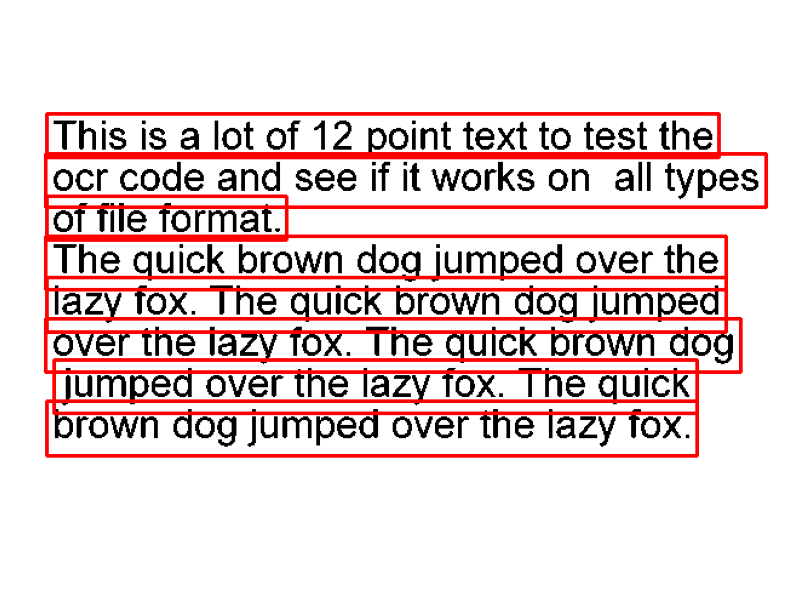

This is a lot of 12 point text to test the
ogr code and see if it works on all types
of file format.
The quick brown dog jumped over the
lazy fox. The quick brown dog jumped
over the lazy fox. The quick brown dog
jumped over the lazy fox. The quick 
brown dog jumped over the lazy fox.


In [13]:
ckpt = torch.load('crnn_ocr_best.pt', map_location=device)
model.load_state_dict(ckpt['model']); model.eval()

def segment_lines(gray, min_h=8):
    blur = cv2.GaussianBlur(gray, (3, 3), 0)
    _, bw = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)   # text = white
    if bw.mean() > 127: bw = 255 - bw                                              # light text on dark bg
    proj = (bw > 0).sum(1)
    rows = proj > max(1, 0.01 * bw.shape[1])
    lines, start = [], None
    for i, r in enumerate(list(rows) + [False]):
        if r and start is None: start = i
        elif not r and start is not None:
            if i - start >= min_h:
                cols = np.where((bw[start:i] > 0).any(0))[0]
                pad = max(2, (i - start) // 4)
                y0, y1 = max(0, start - pad), min(gray.shape[0], i + pad)
                x0, x1 = max(0, cols[0] - pad), min(gray.shape[1], cols[-1] + pad)
                lines.append((y0, y1, x0, x1))
            start = None
    return lines

@torch.no_grad()
def ocr_line(gray_crop):
    h, w = gray_crop.shape
    new_w = max(8, int(round(w * IMG_H / h)))          # no width cap at inference
    g = cv2.resize(gray_crop if gray_crop.mean() >= 127 else 255 - gray_crop, (new_w, IMG_H), interpolation=cv2.INTER_AREA)
    x = torch.from_numpy(1.0 - g.astype(np.float32) / 255.0)[None, None].to(device)
    return greedy_decode(model(x))[0]

def ocr_image(path, show=True):
    gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    lines = segment_lines(gray)
    text = [ocr_line(gray[y0:y1, x0:x1]) for y0, y1, x0, x1 in lines]
    if show:
        vis = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
        for y0, y1, x0, x1 in lines: cv2.rectangle(vis, (x0, y0), (x1, y1), (255, 0, 0), 2)
        plt.figure(figsize=(10, 10)); plt.imshow(vis); plt.axis('off'); plt.show()
    return '\n'.join(text)

from google.colab import files
up = files.upload()
for name in up:
    print(ocr_image(name))

## 9. Where to go next
- **More/better data:** more fonts (download Google Fonts), backgrounds/paper textures, perspective warps, or real labelled data (e.g. IAM for handwriting, SROIE for receipts).
- **Beam search decoding + language model** (e.g. `pyctcdecode` with a KenLM model) — fixes many near-miss words.
- **Better line/word detection:** replace the projection-profile segmenter with a text detector (DBNet / CRAFT) for photos, multi-column pages, or skewed text.
- **Stronger recogniser:** swap the BiLSTM for a Transformer encoder, or try an attention decoder / ViT-based model (TrOCR-style).
- **Fine-tune on your domain:** if you have real images of the documents you care about, label a few hundred lines and fine-tune from `crnn_ocr_best.pt` with a lower LR.
